# Phase 6: Candidate Scoring and Skill Gap Analysis

This notebook demonstrates the Phase 6 explainable ranking system.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from src.scoring import analyze_skill_gap, calculate_candidate_score, rank_candidates

plt.style.use('ggplot')
sns.set_theme(style="whitegrid")


## 2-4. Data Loading and Skill Adapters

We load the pre-processed Phase 2/4 data and simulate Phase 3 extracted skills since the real Phase 3 pipeline output format is abstracted here via adapters.

In [2]:
# Simulated Job Requirements
job_reqs = {
    "job_id": "J101",
    "title": "Data Scientist",
    "required_skills": ["Python", "Machine Learning", "SQL", "Pandas"],
    "optional_skills": ["AWS", "Docker", "Git"]
}

# Simulated Candidates with Phase 4 Baseline Scores and Phase 3 Skills
candidates = [
    {
        "candidate_id": "C001",
        "candidate_skills": ["Python", "SQL", "Pandas", "Machine Learning", "Git", "Tableau"],
        "baseline_match_score": 0.85
    },
    {
        "candidate_id": "C002",
        "candidate_skills": ["Python", "SQL", "Java", "C++"],
        "baseline_match_score": 0.60
    },
    {
        "candidate_id": "C003",
        "candidate_skills": ["Python", "Machine Learning", "Deep Learning", "NLP", "AWS", "Docker"],
        "baseline_match_score": 0.78
    },
    {
        "candidate_id": "C004",
        "candidate_skills": ["Excel", "Word", "PowerPoint"],
        "baseline_match_score": 0.15
    }
]

df_cands = pd.DataFrame(candidates)
display(df_cands)


,candidate_id,candidate_skills,baseline_match_score
0,C001,"[Python, SQL, Pandas, Machine Learning, Git, T...",0.85
1,C002,"[Python, SQL, Java, C++]",0.60
2,C003,"[Python, Machine Learning, Deep Learning, NLP,...",0.78
3,C004,"[Excel, Word, PowerPoint]",0.15


## 5. Skill Normalization

Demonstrating the normalization mapping (e.g. 'ML' -> 'machine learning').

In [3]:
from src.scoring.skill_gap import normalize_skill
print("Normalizing 'ML':", normalize_skill("ML"))
print("Normalizing ' Machine-Learning ':", normalize_skill(" Machine-Learning "))


Normalizing 'ML': machine learning
Normalizing ' Machine-Learning ': machine learning


## 6-8. Skill Comparison and Missing Skill Detection

Calculating matches, missing, and additional skills for Candidate C003.

In [4]:
cand = candidates[2]
gap = analyze_skill_gap(cand["candidate_skills"], job_reqs["required_skills"], job_reqs["optional_skills"])

import json
print(json.dumps(gap, indent=2))


{
  "matched_required": [
    "machine learning",
    "python"
  ],
  "matched_optional": [
    "amazon web services",
    "docker"
  ],
  "missing_required": [
    "pandas",
    "sql"
  ],
  "missing_optional": [
    "git"
  ],
  "additional_skills": [
    "deep learning",
    "natural language processing"
  ],
  "match_percentage": 50.0
}


## 9-13. Candidate Scoring, Ranking, and Explainability

Aggregating the skill gap and Phase 4 baseline text score into an overall explainable ranking.

In [5]:
ranked = rank_candidates(candidates, job_reqs)

df_ranked = pd.DataFrame(ranked)
# Display key columns
display(df_ranked[['candidate_id', 'overall_score', 'recommendation', 'skill_match_percentage', 'missing_required_skills']])


,candidate_id,overall_score,recommendation,skill_match_percentage,missing_required_skills
0,C001,94.0,Strong Match,100.0,[]
1,C003,61.2,Moderate Match,50.0,"[pandas, sql]"
2,C002,54.0,Potential Match,50.0,"[machine learning, pandas]"
3,C004,6.0,Low Match,0.0,"[machine learning, pandas, python, sql]"


## 14. Edge Case Handling

Testing with empty skill lists and zero overlap.

In [6]:
empty_cand = [{"candidate_id": "C_EMPTY", "candidate_skills": [], "baseline_match_score": 0.0}]
print(rank_candidates(empty_cand, job_reqs)[0]["recommendation"])


Low Match


## 15. Visualization of Score Distributions

Plotting the breakdown of the scores to understand what drove the ranking.

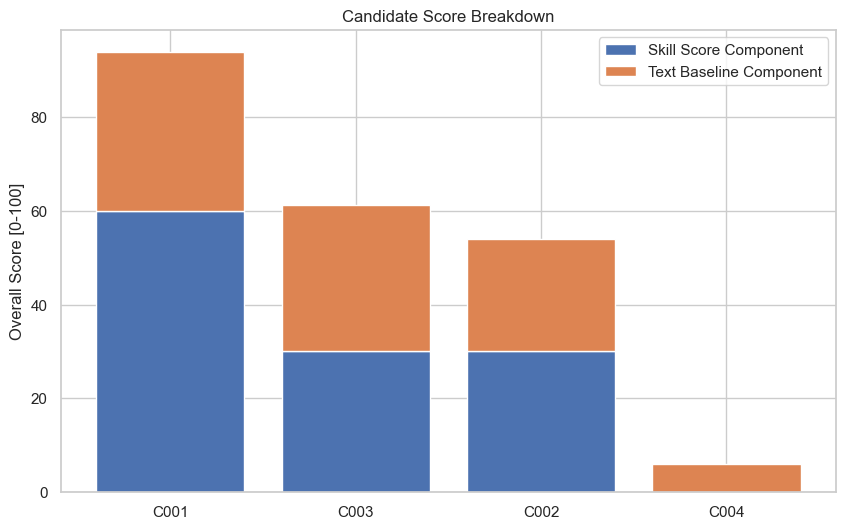

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

cand_ids = [r['candidate_id'] for r in ranked]
skill_contrib = [r['score_breakdown']['skill_contribution'] for r in ranked]
text_contrib = [r['score_breakdown']['baseline_text_contribution'] for r in ranked]

p1 = ax.bar(cand_ids, skill_contrib, label='Skill Score Component')
p2 = ax.bar(cand_ids, text_contrib, bottom=skill_contrib, label='Text Baseline Component')

ax.set_title("Candidate Score Breakdown")
ax.set_ylabel("Overall Score [0-100]")
ax.legend()
plt.show()


## 16-17. Phase 5 Integration & Conclusions

- The system successfully merges deterministic skill checks with fuzzy ML text matching.
- **Phase 5 Integration:** The `calculate_candidate_score` and `rank_candidates` functions accept an optional `semantic_score` parameter. When provided, the weights dynamically shift (e.g., 40% skills, 40% semantic, 20% baseline) without requiring a rewrite.
- Explainable outputs ensure the frontend can show *why* a candidate was recommended (e.g. listing exactly what required skills are missing).